### Ансамблирование: Введение

**Ансамблирование** (Ensembling) - это мощный подход в машинном обучении, который заключается в объединении предсказаний нескольких базовых моделей (так называемых "слабых учеников" или "базовых классификаторов") для получения более точной и надежной общей модели. Основная идея состоит в том, что коллективное решение группы моделей, как правило, превосходит решение любой отдельной модели.

#### Основные преимущества ансамблевых методов:

1.  **Повышение точности (Accuracy Improvement):** Объединение предсказаний нескольких моделей помогает усреднить или агрегировать их индивидуальные результаты, что часто приводит к более точным и надежным предсказаниям, чем у любой одной модели.

2.  **Снижение переобучения (Reduced Overfitting):** Ансамблевые методы, такие как бэггинг (например, случайный лес), помогают снизить переобучение за счет усреднения множества моделей, каждая из которых обучается на немного разных подмножествах данных. Это уменьшает дисперсию (variance) модели.

3.  **Улучшение устойчивости моделей (Improved Robustness):** Когда отдельные модели совершают ошибки или дают неправильные предсказания, другие модели в ансамбле могут компенсировать эти ошибки, делая итоговое предсказание более устойчивым и менее чувствительным к шуму или аномалиям в данных.

В этой работе все методы применяются к датасету **о кофе** (`coffee_value_benchmark.csv`): по характеристикам партии (страна, высота плантации, способ обработки, хранение и т.д.) мы предсказываем **оценку качества кофе** `coffee_quality_score`.

### Объяснение принципов Бэггинга (Bootstrap Aggregating)

Бэггинг (Bootstrap Aggregating) — это ансамблевый метод машинного обучения, разработанный для уменьшения дисперсии (variance) модели, что помогает избежать переобучения и улучшить стабильность предсказаний. Он основан на двух ключевых понятиях: бутстрап-выборке и агрегировании.

#### 1. Бутстрап-выборка (Bootstrap Sampling)

Бутстрап-выборка — это статистическая процедура, которая позволяет создавать несколько подмножеств данных из исходного набора данных. Основные характеристики бутстрап-выборки:

*   **С замещением**: Элементы выбираются из исходного набора данных случайным образом, и каждый выбранный элемент возвращается обратно в набор, что означает, что один и тот же элемент может быть выбран несколько раз для одного подмножества.
*   **Размер подмножества**: Каждое подмножество обычно имеет тот же размер, что и исходный набор данных, но поскольку выборка происходит с замещением, каждое подмножество будет содержать примерно 63.2% уникальных экземпляров из исходного набора, а остальные будут дубликатами.



## Загрузка и подготовка датасета про кофе

Архив `archive.zip` содержит 4 файла:

*   `coffee_value_benchmark.csv` — основная таблица (характеристики партий кофе и целевые переменные);
*   `coffee_benchmark_splits.csv` — готовое разбиение партий (`lot_id`) на `Train` и `Test (Temporal)` по времени урожая;
*   `coffee_record_metadata.csv` — тип записи (`Original`, `Exact Duplicate`, `Measurement Revision`);
*   `feature_dictionary.csv` — описание признаков и то, какие из них можно использовать для предсказания качества.

**Целевая переменная:** `coffee_quality_score` (оценка качества, регрессия).

In [ ]:
import os, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


if os.path.exists('archive.zip') and not os.path.exists('coffee_value_benchmark.csv'):
    with zipfile.ZipFile('archive.zip') as z:
        z.extractall('.')

df = pd.read_csv('coffee_value_benchmark.csv')
splits = pd.read_csv('coffee_benchmark_splits.csv')
meta = pd.read_csv('coffee_record_metadata.csv')
fdict = pd.read_csv('feature_dictionary.csv')

print(f"Shape of df: {df.shape}")
print(f"Shape of splits: {splits.shape}")
print(f"Shape of meta: {meta.shape}")
df.head()

Shape of df: (35700, 36)
Shape of splits: (35000, 2)
Shape of meta: (35700, 3)


,record_id,lot_id,harvest_season,harvest_calendar_year,harvest_month,country_of_origin,farm_type,farm_size_hectares,tree_age_years,altitude_mean_meters,...,lot_size_kg,roast_level,acidity_score,sweetness_score,body_score,aroma_score,flavor_score,coffee_quality_score,quality_grade,price_usd_per_kg
0,REC-0000001,LOT-0032936,2020/21,2020,10,Vietnam,Smallholder,0.58,28.0,1961.0,...,26433.0,Medium,7.95,7.30,8.45,7.35,7.37,78.01,Very Good,2.43
1,REC-0000002,LOT-0030952,2021/22,2022,1,Honduras,Smallholder,1.12,2.0,1257.0,...,25446.0,Medium,7.62,8.17,7.45,7.80,6.88,75.62,Good,4.06
2,REC-0000003,LOT-0018572,2020/21,2020,11,Vietnam,Cooperative,13.82,5.0,557.0,...,15707.0,Medium,8.47,8.83,8.13,7.70,8.10,72.41,Commercial,4.26
3,REC-0000004,LOT-0005318,2021/22,2021,10,Vietnam,Cooperative,9.96,22.0,652.0,...,2879.0,Medium,7.54,8.12,8.21,7.77,7.13,75.67,Good,3.60
4,REC-0000005,LOT-0006317,2021/22,2021,7,Brazil,Smallholder,1.90,11.0,971.0,...,9561.0,Medium,6.70,8.08,8.68,7.38,7.16,73.77,Good,4.16


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
print(meta['record_type'].value_counts())
print()
print(splits['temporal_split'].value_counts())
print()
print("Пропуски в данных:")
na = df.isna().sum()
print(na[na > 0])

record_type
Original                35000
Measurement Revision      350
Exact Duplicate           350
Name: count, dtype: int64

temporal_split
Train              29638
Test (Temporal)     5362
Name: count, dtype: int64

Пропуски в данных:
avg_annual_rainfall_mm     1819
humidity_pct               2282
moisture_pct               1612
bean_density_g_ml          1632
certification             21723
dtype: int64


#### Очистка данных

В таблице есть строки типов `Exact Duplicate` (точные дубликаты) и `Measurement Revision` (повторные измерения той же партии). Если их оставить, одна и та же партия может попасть и в обучающую, и в тестовую выборку, а модель будет "подсматривать" ответ. Поэтому оставляем только оригинальные записи (`Original`) — по одной на партию — и используем готовое **временное** разбиение: обучаемся на ранних урожаях, проверяем на поздних (это честнее, чем случайное разбиение).

In [ ]:
data = (df.merge(meta[['record_id', 'record_type']], on='record_id')
          .merge(splits, on='lot_id'))
data = data[data['record_type'] == 'Original'].reset_index(drop=True)

print(f"После очистки: {data.shape}")
print(data['temporal_split'].value_counts())
print()
print(data.groupby('temporal_split')['harvest_calendar_year'].agg(['min', 'max']))

После очистки: (35000, 38)
temporal_split
Train              29638
Test (Temporal)     5362
Name: count, dtype: int64

                  min   max
temporal_split             
Test (Temporal)  2023  2024
Train            2019  2023


#### Выбор признаков

Согласно `feature_dictionary.csv`, у каждого признака есть пометка `usable_as_feature_for_quality`. Берем только признаки, которые можно использовать для предсказания качества. Сенсорные оценки (`acidity_score`, `flavor_score` и т.д.) — это уже результат дегустации, их использовать нельзя (утечка целевой переменной). Коммерческие признаки (цена, сертификаты) тоже исключены.

In [ ]:
target = 'coffee_quality_score'

features = fdict.loc[fdict['usable_as_feature_for_quality'] == True, 'column'].tolist()
cat_features = [c for c in features if data[c].dtype == 'object' or str(data[c].dtype) in ('str', 'category')]
num_features = [c for c in features if c not in cat_features]

print(f"Признаков всего: {len(features)}")
print("Числовые:", num_features)
print("Категориальные:", cat_features)

Признаков всего: 21
Числовые: ['harvest_calendar_year', 'harvest_month', 'farm_size_hectares', 'tree_age_years', 'altitude_mean_meters', 'avg_temp_c', 'avg_annual_rainfall_mm', 'humidity_pct', 'drying_duration_days', 'storage_months', 'bean_size_screen', 'moisture_pct', 'bean_density_g_ml', 'defect_rate_pct']
Категориальные: ['harvest_season', 'country_of_origin', 'farm_type', 'species', 'processing_method', 'drying_method', 'storage_conditions']


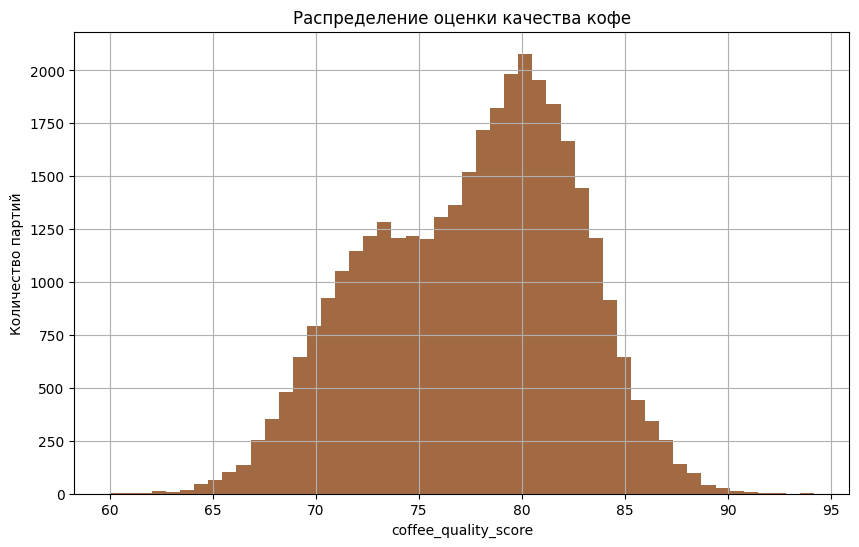

count    35000.000000
mean        77.598767
std          4.915882
min         60.000000
25%         73.807500
50%         78.230000
75%         81.320000
max         94.180000
Name: coffee_quality_score, dtype: float64


In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(data[target], bins=50, color='saddlebrown', alpha=0.8)
plt.title('Распределение оценки качества кофе')
plt.xlabel('coffee_quality_score')
plt.ylabel('Количество партий')
plt.grid(True)
plt.show()

print(data[target].describe())

In [ ]:

train = data[data['temporal_split'] == 'Train']
test = data[data['temporal_split'] != 'Train']

X_train_full = pd.get_dummies(train[features], columns=cat_features, dtype=float)
X_test_full = pd.get_dummies(test[features], columns=cat_features, dtype=float)
X_test_full = X_test_full.reindex(columns=X_train_full.columns, fill_value=0.0)

medians = X_train_full.median()
X_train_full = X_train_full.fillna(medians)
X_test_full = X_test_full.fillna(medians)

y_train_full = train[target].values
y_test_full = test[target].values

print(f"X_train: {X_train_full.shape}, X_test: {X_test_full.shape}")

X_train: (29638, 39), X_test: (5362, 39)


## Обоснование бэггинга через дисперсию

Сначала посмотрим на эффект бэггинга на простом примере с **одним признаком** — высотой плантации (`altitude_mean_meters`). Берем подвыборку из 300 партий, чтобы график был читаемым. Базовая модель — неглубокое дерево решений.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.model_selection import train_test_split


np.random.seed(42)
sample = data.dropna(subset=['altitude_mean_meters']).sample(300, random_state=42)

X = sample[['altitude_mean_meters']].values
y = sample[target].values

print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

Shape of X: (300, 1)
Shape of y: (300,)


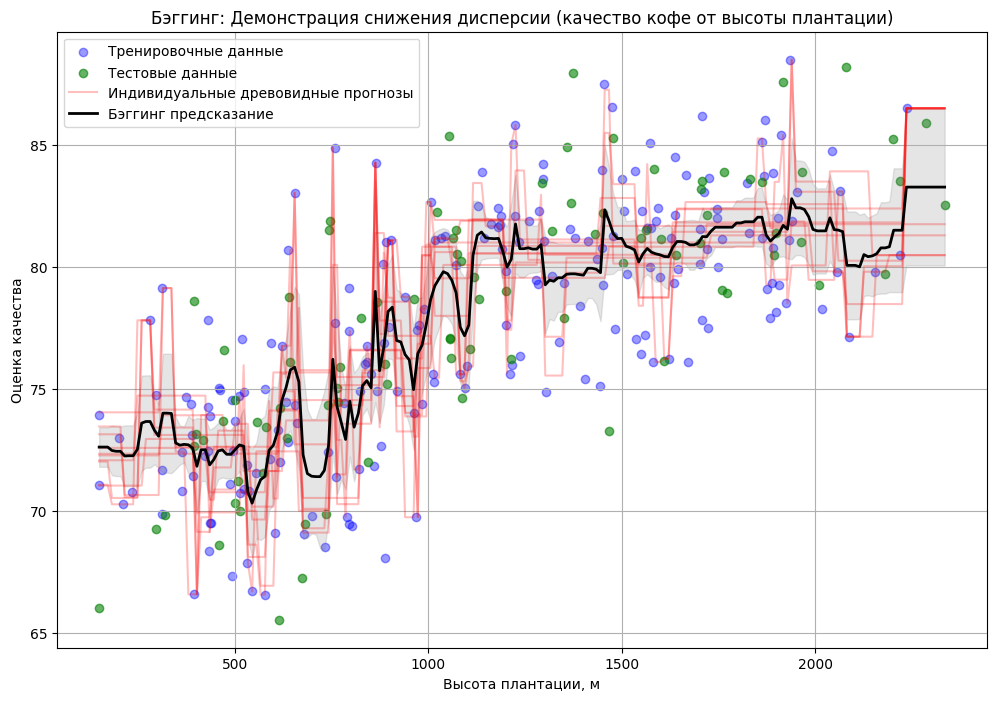

Демонстрация бэггинга и график снижения отклонений


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

individual_tree_predictions = []

n_estimators = 100

X_plot = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

for i in range(n_estimators):

    bootstrap_indices = np.random.choice(len(X_train), len(X_train), replace=True)
    X_bootstrap, y_bootstrap = X_train[bootstrap_indices], y_train[bootstrap_indices]

    tree = DecisionTreeRegressor(max_depth=5, random_state=i)
    tree.fit(X_bootstrap, y_bootstrap)

    individual_tree_predictions.append(tree.predict(X_plot))

individual_tree_predictions = np.array(individual_tree_predictions)


mean_predictions = np.mean(individual_tree_predictions, axis=0)
std_predictions = np.std(individual_tree_predictions, axis=0)

plt.figure(figsize=(12, 8))

plt.scatter(X_train, y_train, label='Тренировочные данные', color='blue', alpha=0.4)
plt.scatter(X_test, y_test, label='Тестовые данные', color='green', alpha=0.6)

num_trees_to_plot = 10
for i in range(num_trees_to_plot):
    plt.plot(X_plot, individual_tree_predictions[i], color='red', alpha=0.25,
             label='Индивидуальные древовидные прогнозы' if i == 0 else "")

plt.plot(X_plot, mean_predictions, color='black', linewidth=2, label='Бэггинг предсказание')

plt.fill_between(X_plot.flatten(),
                 mean_predictions - std_predictions,
                 mean_predictions + std_predictions,
                 color='gray', alpha=0.2)

plt.title('Бэггинг: Демонстрация снижения дисперсии (качество кофе от высоты плантации)')
plt.xlabel('Высота плантации, м')
plt.ylabel('Оценка качества')
plt.legend()
plt.grid(True)
plt.show()

print("Демонстрация бэггинга и график снижения отклонений")

## Реализация бэггинга с помощью Scikit-learn

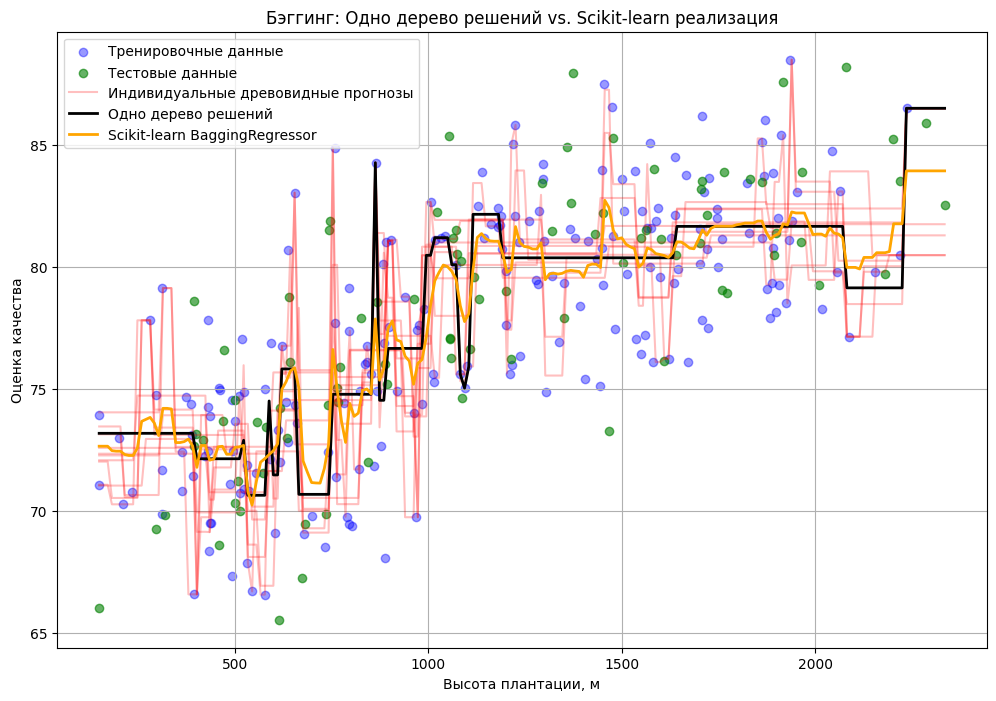

MSE одного дерева (тест):     13.118
MSE BaggingRegressor (тест):  11.202


In [ ]:
from sklearn.metrics import mean_squared_error

single_tree = DecisionTreeRegressor(max_depth=5, random_state=42).fit(X_train, y_train)

bagging_sk = BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=5, random_state=42),
                              n_estimators=100, random_state=42)


bagging_sk.fit(X_train, y_train)


predictions_sk = bagging_sk.predict(X_test)


predictions_sk_plot = bagging_sk.predict(X_plot)

plt.figure(figsize=(12, 8))

plt.scatter(X_train, y_train, label='Тренировочные данные', color='blue', alpha=0.4)
plt.scatter(X_test, y_test, label='Тестовые данные', color='green', alpha=0.6)

for i in range(num_trees_to_plot):
    plt.plot(X_plot, individual_tree_predictions[i], color='red', alpha=0.25,
             label='Индивидуальные древовидные прогнозы' if i == 0 else "")

plt.plot(X_plot, single_tree.predict(X_plot), color='black', linewidth=2, label='Одно дерево решений')
plt.plot(X_plot, predictions_sk_plot, color='orange', linewidth=2, label='Scikit-learn BaggingRegressor')

plt.title('Бэггинг: Одно дерево решений vs. Scikit-learn реализация')
plt.xlabel('Высота плантации, м')
plt.ylabel('Оценка качества')
plt.legend()
plt.grid(True)
plt.show()

print(f"MSE одного дерева (тест):     {mean_squared_error(y_test, single_tree.predict(X_test)):.3f}")
print(f"MSE BaggingRegressor (тест):  {mean_squared_error(y_test, predictions_sk):.3f}")

## Random Forest: детали реализации

### Random Forest: Подробное рассмотрение

Random Forest — это мощный и популярный ансамблевый метод машинного обучения, который является расширением бэггинга. Он использует несколько деревьев решений в качестве базовых учеников и вводит дополнительную случайность для повышения производительности и снижения переобучения.

#### Основные принципы Random Forest:

1.  **Бэггинг (Bootstrap Aggregating)**:
    Как и в бэггинге, Random Forest строит каждое дерево на основе **бутстрап-выборки** (bootstrap sample) из исходного обучающего набора данных. Это означает, что для обучения каждого дерева случайным образом с замещением выбираются подмножества данных. Это обеспечивает разнообразие среди деревьев, так как каждое дерево видит немного разный набор обучающих примеров.

2.  **Рандомизация по признакам (Feature Randomization / Random Subspace Method)**:
    Это ключевое отличие Random Forest от обычного бэггинга деревьев. При построении каждого отдельного дерева решений, на каждом узле, где требуется найти оптимальное разделение, алгоритм выбирает не все доступные признаки, а **случайное подмножество признаков**. Затем из этого подмножества выбирается лучший признак для разделения. Этот процесс повторяется на каждом узле каждого дерева.

    *   **Почему это важно?** Если в наборе данных есть один или несколько очень сильных признаков, то в обычном бэггинге большинство деревьев будут выбирать эти признаки в качестве первых узлов, что приведет к созданию очень похожих деревьев. Эти сильно коррелированные деревья будут иметь похожие ошибки, и их усреднение не приведет к значительному снижению дисперсии. Рандомизация по признакам "заставляет" каждое дерево исследовать разные аспекты данных, уменьшая корреляцию между деревьями и, следовательно, значительно снижая общую дисперсию ансамбля.

3.  **Построение множества деревьев (Ensemble of Decision Trees)**:
    Random Forest строит большое количество деревьев решений (например, 100, 500 или даже больше). Каждое дерево обучается независимо от других, используя свою бутстрап-выборку данных и случайное подмножество признаков для каждого разделения.

4.  **Агрегирование предсказаний**:
    После обучения всех деревьев, их предсказания агрегируются для получения окончательного результата:
    *   **Для задач классификации**: Используется **голосование большинством** (majority voting). Класс, который предсказан наибольшим количеством деревьев, становится окончательным предсказанием.
    *   **Для задач регрессии**: Используется **усреднение** (averaging) предсказаний всех деревьев.

#### Вклад в снижение переобучения и улучшение производительности:

*   **Снижение переобучения**: Сочетание бэггинга и рандомизации признаков приводит к созданию разнообразного ансамбля деревьев. Каждое дерево имеет высокий уровень дисперсии, но когда их предсказания усредняются, индивидуальные ошибки и переобучение каждого дерева компенсируются, что приводит к более стабильной и обобщающей модели.
*   **Повышение точности**: За счет уменьшения корреляции между деревьями, Random Forest способен достигать более высокой точности по сравнению с отдельными деревьями или простым бэггингом, особенно на сложных наборах данных.

### Ключевые параметры и аспекты реализации Random Forest

Random Forest, являясь расширением бэггинга, использует ансамбль деревьев решений, обученных на бутстрэп-выборках данных, с дополнительным элементом случайности – случайным выбором подмножества признаков при каждом разделении узла. Эта дополнительная случайность помогает уменьшить корреляцию между деревьями, что является ключом к снижению дисперсии ансамбля.

Рассмотрим основные параметры и аспекты реализации:

1.  **n_estimators (количество деревьев)**:
    *   **Описание**: Определяет количество деревьев решений, которые будут построены в ансамбле. Чем больше деревьев, тем более стабильным и точным, как правило, становится ансамбль.
    *   **Влияние**: Увеличение `n_estimators` обычно повышает производительность модели (снижает ошибку), но после определенного момента улучшение становится незначительным, а вычислительные затраты (время обучения и предсказания, потребление памяти) продолжают расти. Оптимальное количество деревьев можно найти с помощью кросс-валидации или мониторинга OOB-ошибки.

2.  **max_depth (максимальная глубина дерева)**:
    *   **Описание**: Ограничивает максимальную глубину каждого отдельного дерева в лесу. По умолчанию деревья строятся до тех пор, пока листья не станут чистыми или не будут содержать `min_samples_leaf` образцов.
    *   **Влияние**: Глубокие деревья склонны к переобучению на обучающих данных (высокая дисперсия, низкое смещение). Ограничение `max_depth` помогает уменьшить переобучение отдельных деревьев, тем самым способствуя снижению дисперсии ансамбля. Слишком малая глубина может привести к недообучению (высокое смещение).

3.  **max_features (количество признаков для разделения)**:
    *   **Описание**: Определяет количество признаков, которые будут случайно выбраны при поиске лучшего разбиения для каждого узла. Это ключевая особенность Random Forest, которая отличает его от обычного бэггинга.
    *   **Влияние**: Случайный выбор подмножества признаков существенно снижает корреляцию между отдельными деревьями в ансамбле, поскольку это уменьшает вероятность того, что все деревья будут выбирать одни и те же сильные признаки для разбиения верхних узлов. Снижение корреляции между деревьями приводит к более эффективному снижению общей дисперсии ансамбля.
    *   **Типичные значения**:
        *   **Классификация**: `sqrt` (квадратный корень из общего числа признаков) или `log2` (логарифм по основанию 2).
        *   **Регрессия**: `1.0` (все признаки), `sqrt`, `p/3` (где p - общее количество признаков).

4.  **min_samples_split и min_samples_leaf (минимальное количество выборок для разделения и в листе)**:
    *   **min_samples_split**: Минимальное количество образцов, необходимое для того, чтобы узел мог быть разделен. Если в узле меньше образцов, он не будет разделен, становясь листом.
    *   **min_samples_leaf**: Минимальное количество образцов, которое должно быть в каждом листе после разделения. Если разделение приведет к листу с меньшим количеством образцов, такое разделение будет отклонено.
    *   **Влияние**: Эти параметры служат для контроля сложности каждого дерева и предотвращения излишнего ветвления. Они напрямую влияют на степень переобучения: увеличение этих значений делает деревья менее сложными и более устойчивыми к шуму.

5.  **criterion (критерий разбиения)**:
    *   **Описание**: Функция, используемая для измерения качества разбиения узла. Алгоритм пытается найти такое разбиение, которое максимизирует уменьшение неопределенности или ошибки.
    *   **Для классификации**:
        *   **'gini' (индекс Джини)**: Мера чистоты узла. Предпочитает изолировать наиболее частый класс в каждой ветви.
        *   **'entropy' (энтропия)**: Мера неопределенности или хаоса. Стремится создать узлы с максимально однородным распределением классов.
    *   **Для регрессии**:
        *   **'squared_error' (ранее 'mse' - Mean Squared Error)**: Минимизирует средний квадрат ошибок.
        *   **'absolute_error' (ранее 'mae' - Mean Absolute Error)**: Минимизирует средний абсолютный ошибку.

6.  **oob_score (оценка 'out-of-bag')**:
    *   **Описание**: Random Forest может использовать объекты, которые не попали в бутстрэп-выборку для обучения конкретного дерева (out-of-bag samples), для внутренней оценки производительности модели. Для каждого объекта обучающей выборки собираются предсказания только тех деревьев, для обучения которых этот объект не использовался. Затем эти предсказания агрегируются для получения OOB-оценки.
    *   **Влияние**: `oob_score` позволяет оценить обобщающую способность модели без использования отдельного валидационного набора данных, что особенно полезно при ограниченном объеме данных. Если `oob_score` установлен в `True`, после обучения модели атрибут `oob_score_` будет содержать оценку.

Понимание и правильная настройка этих параметров критически важны для достижения оптимальной производительности Random Forest, балансируя между смещением и дисперсией модели.

#### Random Forest на полном датасете о кофе

Теперь используем все доступные признаки партии и временное разбиение (`Train` / `Test (Temporal)`), подготовленные выше.

In [ ]:
print(f"Shape X_train_full: {X_train_full.shape}")
print(f"Shape y_train_full: {y_train_full.shape}")
print(f"Shape X_test_full:  {X_test_full.shape}")
print(f"Shape y_test_full:  {y_test_full.shape}")

Shape X_train_full: (29638, 39)
Shape y_train_full: (29638,)
Shape X_test_full:  (5362, 39)
Shape y_test_full:  (5362,)


Cреднеквадратичная ошибка RandomForestRegressor: 3.10
R^2 на тесте: 0.871


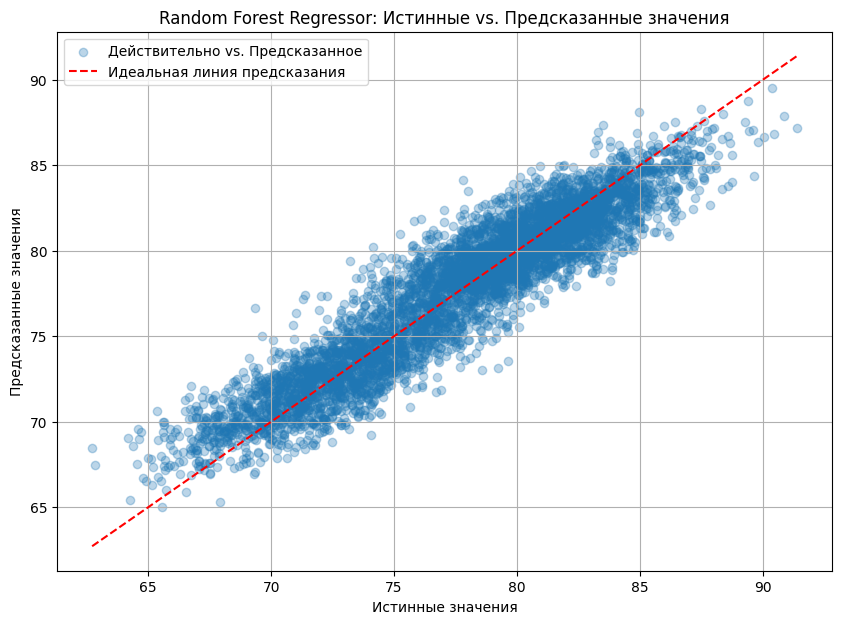

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)


rf_model.fit(X_train_full, y_train_full)


y_pred_rf = rf_model.predict(X_test_full)


mse_rf = mean_squared_error(y_test_full, y_pred_rf)
print(f"Cреднеквадратичная ошибка RandomForestRegressor: {mse_rf:.2f}")
print(f"R^2 на тесте: {r2_score(y_test_full, y_pred_rf):.3f}")

plt.figure(figsize=(10, 7))
plt.scatter(y_test_full, y_pred_rf, alpha=0.3, label='Действительно vs. Предсказанное')

min_val = min(y_test_full.min(), y_pred_rf.min())
max_val = max(y_test_full.max(), y_pred_rf.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Идеальная линия предсказания')

plt.title('Random Forest Regressor: Истинные vs. Предсказанные значения')
plt.xlabel('Истинные значения')
plt.ylabel('Предсказанные значения')
plt.legend()
plt.grid(True)
plt.show()

#### Сравнение: одно дерево, бэггинг и случайный лес на всех признаках

In [ ]:
from sklearn.metrics import mean_absolute_error

models = {
    'Одно дерево (depth=10)': DecisionTreeRegressor(max_depth=10, random_state=42),
    'Бэггинг (100 деревьев)': BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=10, random_state=42),
                                                n_estimators=100, random_state=42, n_jobs=-1),
    'Random Forest (100 деревьев)': RandomForestRegressor(n_estimators=100, max_depth=10, max_features=0.5,
                                                          random_state=42, n_jobs=-1),
}

rows = []
for name, model in models.items():
    model.fit(X_train_full, y_train_full)
    pred = model.predict(X_test_full)
    rows.append({'Модель': name,
                 'MSE': mean_squared_error(y_test_full, pred),
                 'MAE': mean_absolute_error(y_test_full, pred),
                 'R2': r2_score(y_test_full, pred)})

results = pd.DataFrame(rows).set_index('Модель').round(3)
results

,MSE,MAE,R2
Модель,,,
Одно дерево (depth=10),3.841,1.547,0.840
Бэггинг (100 деревьев),3.103,1.396,0.871
Random Forest (100 деревьев),3.204,1.422,0.867


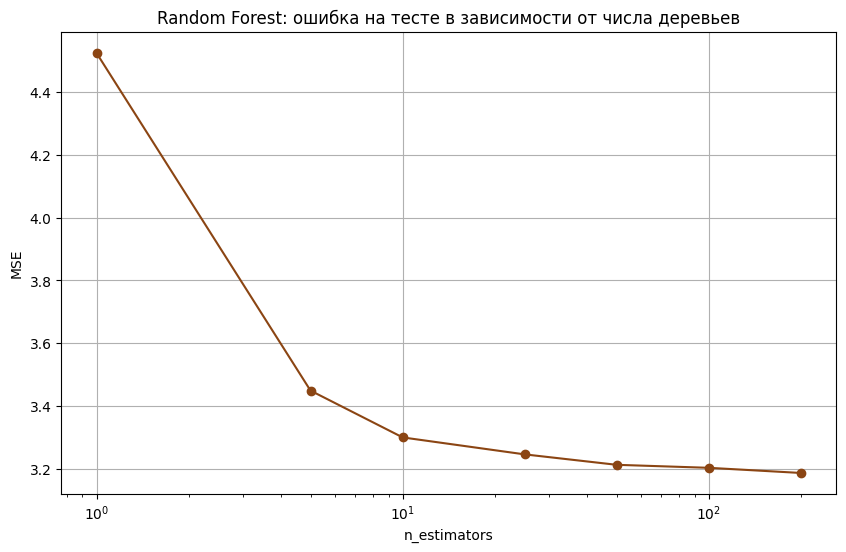

In [ ]:

n_list = [1, 5, 10, 25, 50, 100, 200]
test_mse = []
for n in n_list:
    m = RandomForestRegressor(n_estimators=n, max_depth=10, max_features=0.5, random_state=42, n_jobs=-1)
    m.fit(X_train_full, y_train_full)
    test_mse.append(mean_squared_error(y_test_full, m.predict(X_test_full)))

plt.figure(figsize=(10, 6))
plt.plot(n_list, test_mse, marker='o', color='saddlebrown')
plt.xscale('log')
plt.title('Random Forest: ошибка на тесте в зависимости от числа деревьев')
plt.xlabel('n_estimators')
plt.ylabel('MSE')
plt.grid(True)
plt.show()

#### Out-of-bag оценка

In [ ]:
rf_oob = RandomForestRegressor(n_estimators=200, max_depth=10, max_features=0.5,
                               oob_score=True, random_state=42, n_jobs=-1)
rf_oob.fit(X_train_full, y_train_full)

print(f"OOB R^2 (без отдельной валидации): {rf_oob.oob_score_:.3f}")
print(f"R^2 на временном тесте:            {r2_score(y_test_full, rf_oob.predict(X_test_full)):.3f}")

OOB R^2 (без отдельной валидации): 0.856
R^2 на временном тесте:            0.867


#### Важность признаков

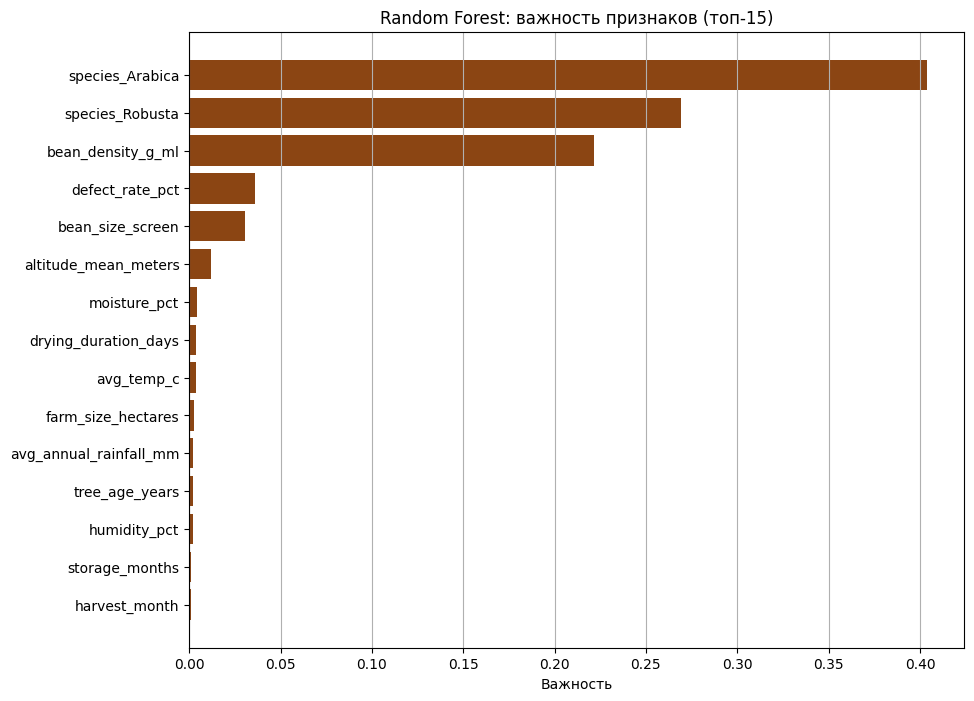

species_Arabica         0.4040
species_Robusta         0.2690
bean_density_g_ml       0.2217
defect_rate_pct         0.0360
bean_size_screen        0.0305
altitude_mean_meters    0.0120
moisture_pct            0.0045
drying_duration_days    0.0039
avg_temp_c              0.0039
farm_size_hectares      0.0024
dtype: float64


In [ ]:
importances = pd.Series(rf_model.feature_importances_, index=X_train_full.columns).sort_values(ascending=False)
top = importances.head(15)[::-1]

plt.figure(figsize=(10, 8))
plt.barh(top.index, top.values, color='saddlebrown')
plt.title('Random Forest: важность признаков (топ-15)')
plt.xlabel('Важность')
plt.grid(True, axis='x')
plt.show()

print(importances.head(10).round(4))

## Заключение:

*   **Преимущества ансамблевого обучения**: Были рассмотрены ансамблевые методы, включая бэггинг и случайный лес, как техники для повышения производительности моделей путем объединения множества базовых алгоритмов. Ключевыми преимуществами являются повышение точности, снижение переобучения (за счет уменьшения дисперсии модели) и увеличение устойчивости к шумам и аномалиям.
*   **Данные о кофе**: Из датасета были удалены дубликаты и повторные измерения (оставлены 35 000 оригинальных записей), использовано временное разбиение (обучение на урожаях 2019–2023, тест на 2023–2024). Для предсказания `coffee_quality_score` взяты только допустимые признаки (без сенсорных оценок и цены, чтобы не было утечки целевой переменной).
*   **Бэггинг (Bootstrap Aggregating)**:
    *   Были объяснены основные принципы бэггинга с акцентом на **бутстрэп-выборку** (случайный выбор с возвращением из обучающих данных) и **агрегацию** (мажоритарное голосование для классификации, усреднение для регрессии).
    *   Практическая демонстрация на зависимости качества от высоты плантации показала, что отдельные деревья решений имеют высокую дисперсию, а усреднение множества деревьев, обученных на бутстрэп-выборках, даёт более гладкий и стабильный прогноз.
*   **Реализация бэггинга в Scikit-learn**: Был обучен `BaggingRegressor`; на тесте он дал меньшую ошибку, чем одно дерево (MSE ≈ 11.2 против ≈ 13.1 в примере с одним признаком).
*   **Алгоритм случайного леса**:
    *   Случайный лес был подробно описан как расширение бэггинга, добавляющее дополнительный уровень случайности за счет использования только **случайного подмножества признаков** для каждого разбиения.
    *   `RandomForestRegressor` (100 деревьев, глубина 10) на всех признаках достиг MSE ≈ 3.10 и R² ≈ 0.87 на временной тестовой выборке.
    *   В сравнении на всех признаках одно дерево дало MSE ≈ 3.84, бэггинг ≈ 3.10, случайный лес с `max_features=0.5` ≈ 3.21. То есть ансамбли заметно лучше одного дерева, а между бэггингом и лесом разница небольшая: в этих данных мало признаков с сильным доминированием, поэтому рандомизация по признакам даёт здесь мало выигрыша.
    *   С ростом числа деревьев ошибка быстро падает и после ~50 деревьев почти перестаёт меняться. OOB-оценка (R² ≈ 0.86) близка к оценке на тесте, то есть может заменять отдельную валидацию.
*   **Важность признаков**: Наибольший вклад в предсказание качества вносят вид кофе (`species`: Arabica/Robusta) и плотность зерна `bean_density_g_ml`, далее идут доля дефектов `defect_rate_pct` и размер зерна `bean_size_screen`.
